# 1.  Iris datasetida birinchi XGBoost modelini yarating

In [2]:
from sklearn.datasets import load_iris
import pandas as pd

# load iris datset
iris = load_iris()
X = iris.data
y = iris.target

# make it tabular using pandas
df = pd.DataFrame(X, columns=iris.feature_names)
df['target'] = y

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [3]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# model training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

xgb = XGBClassifier()
xgb.fit(X_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [4]:
from sklearn.metrics import classification_report, confusion_matrix
y_pred = xgb.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

# Class 0: All 10 samples were correctly classified
# Class 1: 9 samples were correctly classified, but 1 was incorrectly classified as class 2
# Class 2: 9 samples were correctly classified, but 1 was incorrectly classified as class 1

# mini conclusion The model distinguishes class 0 perfectly, while it has some difficulty distinguishing between classes 1 and 2. Overall, the model performed well, with 93% accuracy

# if i say just blindly looking into classification report , but there is note: model confused class 1 with class 2 in both directions. This suggests that these two classes have some similar characteristics, making them slightly harder to distinguish.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


# 2. Hyperparameter tuning — eng yaxshi parametrlarni topamiz

In [7]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 3, 5],
    'subsample': [0.8, 1.0],
}

grid = GridSearchCV(
    estimator=xgb,
    param_grid=params,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)

# Evaluate the best model
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}
Best CV accuracy: 0.9583333333333333
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


In [ ]:
# conclusion:
# Initial model achieved 93.33% accuracy
# GridSearchCV found better hyperparameters
# Tuned model achieved 96.67% accuracy
# It improved by one additional correct prediction

# 3. Overfitting laboratoriyasi: daraxt chuqurligi

In [27]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}
train_set = []
test_set = []
results = []

for k in [1, 2, 3, 5, 8, 12]:
    clf = XGBClassifier(
        learning_rate = 0.05,
        max_depth = k,
        n_estimators= 50,
        subsample = 0.8,
    )
    clf.fit(X_train, y_train)

    print(f'\nModel for k = {k}')
    print(f'Training set score: {clf.score(X_train, y_train)}')
    print(f'Test set score: {clf.score(X_test, y_test)}')
    print(f'Gap = {clf.score(X_train, y_train) - clf.score(X_test, y_test)}')
    train_set.append(clf.score(X_train, y_train))
    test_set.append(clf.score(X_test, y_test))

    results.append({
    'max_depth': k,
    'train_accuracy': clf.score(X_train, y_train),
    'test_accuracy': clf.score(X_test, y_test),
    'gap': clf.score(X_train, y_train) - clf.score(X_test, y_test)
    })


# print in table
results_df = pd.DataFrame(results)
print(results_df)


Model for k = 1
Training set score: 0.9833333333333333
Test set score: 0.9666666666666667
Gap = 0.016666666666666607

Model for k = 2
Training set score: 0.9833333333333333
Test set score: 0.9666666666666667
Gap = 0.016666666666666607

Model for k = 3
Training set score: 0.9833333333333333
Test set score: 0.9666666666666667
Gap = 0.016666666666666607

Model for k = 5
Training set score: 0.9833333333333333
Test set score: 0.9666666666666667
Gap = 0.016666666666666607

Model for k = 8
Training set score: 0.9833333333333333
Test set score: 0.9666666666666667
Gap = 0.016666666666666607

Model for k = 12
Training set score: 0.9833333333333333
Test set score: 0.9666666666666667
Gap = 0.016666666666666607
   max_depth  train_accuracy  test_accuracy       gap
0          1        0.983333       0.966667  0.016667
1          2        0.983333       0.966667  0.016667
2          3        0.983333       0.966667  0.016667
3          5        0.983333       0.966667  0.016667
4          8        0

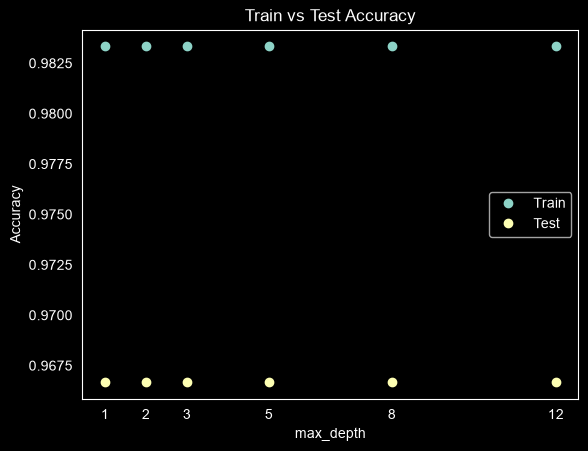

In [11]:
import matplotlib.pyplot as plt

max_depth = [1, 2, 3, 5, 8, 12]

plt.plot(max_depth, train_set, 'o', label='Train')
plt.plot(max_depth, test_set, 'o', label='Test')

plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy')
plt.xticks(max_depth)
plt.legend()
plt.grid()

plt.show()

# 4. Subsampling tajribasi: subsample va colsample_bytree

In [30]:
iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

combinations = [
    (1.0, 1.0),
    (0.8, 1.0),
    (1.0, 0.8),
    (0.8, 0.8)
]
results = []

for subsample, colsample_bytree in combinations:
    xgb = XGBClassifier(
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        random_state=42,
    )
    xgb.fit(X_train, y_train)

    print(f'\nModel for subsample = {subsample}  and colsample_bytree = {colsample_bytree}')
    print(f'Training set score: {xgb.score(X_train, y_train)}')
    print(f'Test set score: {xgb.score(X_test, y_test)}')

    results.append({
        'subsample': subsample,
        'colsample_bytree': colsample_bytree,
        'train_accuracy': xgb.score(X_train, y_train),
        'test_accuracy': xgb.score(X_test, y_test),
        'gap': xgb.score(X_train, y_train) - xgb.score(X_test, y_test)
    })

results_df = pd.DataFrame(results)
print(results_df)


Model for subsample = 1.0  and colsample_bytree = 1.0
Training set score: 1.0
Test set score: 0.9333333333333333

Model for subsample = 0.8  and colsample_bytree = 1.0
Training set score: 1.0
Test set score: 0.9333333333333333

Model for subsample = 1.0  and colsample_bytree = 0.8
Training set score: 1.0
Test set score: 0.9333333333333333

Model for subsample = 0.8  and colsample_bytree = 0.8
Training set score: 1.0
Test set score: 0.9
   subsample  colsample_bytree  train_accuracy  test_accuracy       gap
0        1.0               1.0             1.0       0.933333  0.066667
1        0.8               1.0             1.0       0.933333  0.066667
2        1.0               0.8             1.0       0.933333  0.066667
3        0.8               0.8             1.0       0.900000  0.100000


In [14]:
# now with tuned model , (with hyperparameters)
combinations = [
    (1.0, 1.0),
    (0.8, 1.0),
    (1.0, 0.8),
    (0.8, 0.8)
]

for subsample, colsample_bytree in combinations:
    xgb = XGBClassifier(
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
    )
    xgb.fit(X_train, y_train)

    print(f'\nModel for subsample = {subsample}  and colsample_bytree = {colsample_bytree}')
    print(f'Training set score: {xgb.score(X_train, y_train)}')
    print(f'Test set score: {xgb.score(X_test, y_test)}')


Model for subsample = 1.0  and colsample_bytree = 1.0
Training set score: 1.0
Test set score: 0.9333333333333333

Model for subsample = 0.8  and colsample_bytree = 1.0
Training set score: 1.0
Test set score: 0.9333333333333333

Model for subsample = 1.0  and colsample_bytree = 0.8
Training set score: 1.0
Test set score: 0.9333333333333333

Model for subsample = 0.8  and colsample_bytree = 0.8
Training set score: 1.0
Test set score: 0.9


In [ ]:
# Conclusion:
# I tested four combinations of subsample and colsample_bytree using both default and fixed hyperparameters
# In both experiments, the first three combinations achieved 93.33% test accuracy, while the combination (0.8, 0.8) achieved 90%
# All models achieved 100% training accuracy. Therefore, the combination (0.8, 0.8) had a larger gap between training and test accuracy (10%), while the other combinations had a gap of 6.67%
# Changing the fixed hyperparameters to n_estimators=100, learning_rate=0.1 and max_depth=3 did not change the results in this experiment
# Overall, sampling did not improve test accuracy or reduce the overfitting gap

# 5. Regression: uy narxini bashorat qilish

In [15]:
import numpy as np
import pandas as pd

# Generate 500 houses
np.random.seed(42)
n_samples = 500
df = pd.DataFrame({
    'area_m2': np.random.randint(40, 251, n_samples),
    'rooms': np.random.randint(1, 9, n_samples),
    'age_years': np.random.randint(0, 51, n_samples)
})

# Add random noise to house prices
noise = np.random.normal(0, 15000, n_samples)

# Calculate house prices
df['price'] = (
    50000
    + df['area_m2'] * 1200
    + df['rooms'] * 10000
    - df['age_years'] * 800
    + noise
)

print(df.head())
print(df.shape)
print(df.describe())

   area_m2  rooms  age_years          price
0      142      7         50  237970.129455
1      219      2         38  316224.520775
2      132      5         37  229754.498606
3       54      2         33  122672.710944
4      146      5         37  263933.050193
(500, 4)
          area_m2      rooms   age_years          price
count  500.000000  500.00000  500.000000     500.000000
mean   146.154000    4.36800   25.516000  249775.253349
std     59.914989    2.26425   15.097869   78777.732842
min     40.000000    1.00000    0.000000   66621.229952
25%     92.750000    2.00000   12.000000  187642.533628
50%    148.500000    4.50000   25.500000  251501.777579
75%    197.000000    6.00000   38.250000  314796.057676
max    250.000000    8.00000   50.000000  421751.482205


In [19]:
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

X = df.drop('price', axis=1)
y = df['price']

# split data to train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

xgbr = XGBRegressor(random_state=42)
xgbr.fit(X_train, y_train)

print(mean_absolute_error(y_test, xgbr.predict(X_test)))
print(mean_squared_error(y_test, xgbr.predict(X_test)))

15538.073243326917
410448993.402914


In [20]:
# predict new 3 houses

new_houses = pd.DataFrame({
    'area_m2': [85, 150, 220],
    'rooms': [3, 5, 7],
    'age_years': [5, 12, 2]
})

print(xgbr.predict(new_houses))
# [164155.11 267248.47 384282.94]

[164155.11 267248.47 384282.94]
